# 녹내장 PSM 영상용 시뮬레이션 데이터

영상 「단순 비교의 함정 — 녹내장 복합제는 정말 효과가 없을까?」에 들어가는 모든 수치와 그래프의 출처입니다.

> ⚠️ **모든 데이터는 가상 시뮬레이션 데이터입니다.** 실제 약물의 효과나 임상 결과를 나타내지 않습니다.

설계 목표(대략)
- 기저 안압 평균: 단일제 약 21 vs 복합제 약 28 mmHg
- 단순 비교 목표 안압(18 mmHg 이하) 도달률: 단일제 약 70% vs 복합제 약 55%
- PSM 후 도달률: 단일제 약 60% vs 복합제 약 75%
- 두 군의 기저 안압 분포가 중간 구간에서 충분히 겹치도록

실행하면 작업 폴더의 `data/psm_numbers.json`을 다시 만듭니다. 영상 코드(`src/psm_glaucoma.py`)는 이 파일의 값만 사용합니다.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from sklearn.linear_model import LogisticRegression

# 노트북을 어디서 실행하든 작업 폴더를 찾는다 (현재 폴더와 상위 폴더 탐색)
def find_topic_dir(name="psm_glaucoma_staticstic"):
    for base in [Path.cwd(), *Path.cwd().parents]:
        for cand in (base, base / "videos" / name):
            if cand.name == name and (cand / "src").exists():
                return cand
    raise FileNotFoundError(name)

TOPIC_DIR = find_topic_dir()
DATA_DIR = TOPIC_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)

for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans KR", "Noto Sans CJK KR"]:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = f
        break
plt.rcParams["axes.unicode_minus"] = False

COLOR = {0: "#3987e5", 1: "#eb6834"}   # 단일제 = 파랑, 복합제 = 주황 (영상과 동일)
LABEL = {0: "단일제", 1: "복합제"}
TARGET = 18                              # 목표 안압 (mmHg)

## 1. 가상 환자 만들기

**공변량**: 나이, 녹내장 유형(정상안압 녹내장 여부), 중심각막두께(CCT), 기저 안압
- 정상안압 녹내장 환자는 기저 안압이 낮고, 각막이 두꺼우면 안압이 약간 높게 측정됩니다.

**처방 (교란이 들어가는 곳)**: 기저 안압이 높을수록 복합제를 받을 확률이 높아집니다. 확률이 완만하게 올라가도록 해서, 같은 안압대에서도 두 약이 섞여 처방되게 합니다 (분포 겹침).

**결과 (정답)**: 단일제는 안압을 30%, 복합제는 41% 낮춥니다. 즉 **같은 환자라면 복합제가 더 효과적**입니다. 약에 대한 반응의 개인차는 표준편차 5 mmHg의 잡음으로 넣습니다.

In [2]:
SEED = 0
N = 2000
rng = np.random.default_rng(SEED)

age = rng.normal(64, 10, N).round()
ntg = rng.binomial(1, 0.25, N)                     # 정상안압 녹내장 여부
cct = rng.normal(545, 30, N).round()               # 중심각막두께 (um)
iop0 = rng.normal(25.5, 5.5, N) - 3.5 * ntg + 0.03 * (cct - 545)
iop0 = np.clip(iop0, 10, 42).round(1)              # 기저 안압 (mmHg)

# 처방: 기저 안압이 높을수록 복합제 확률 증가 (기울기를 완만하게 두어 겹침 확보)
lp = -0.2 + 0.5 * (iop0 - 24.5) + 0.02 * (age - 64) - 0.3 * ntg
combo = rng.binomial(1, 1 / (1 + np.exp(-lp)))

# 결과: 정답 효과 — 단일제 30% 하강, 복합제 41% 하강
reduction = np.where(combo == 1, 0.41, 0.30)
iop6 = iop0 * (1 - reduction) + 0.02 * (cct - 545) + rng.normal(0, 5.0, N)

df = pd.DataFrame({"age": age, "ntg": ntg, "cct": cct, "iop0": iop0,
                   "combo": combo, "iop6": iop6.round(1)})
df["reach"] = (df["iop6"] <= TARGET).astype(int)   # 목표 안압 도달 여부
df.groupby("combo").size().rename(index=LABEL).to_frame("환자 수")

,환자 수
combo,
단일제,1040
복합제,960


## 2. 단순 비교

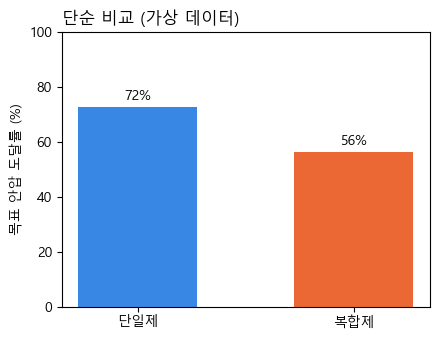

단일제 72.5%  vs  복합제 56.1%


In [3]:
naive = df.groupby("combo")["reach"].mean() * 100

fig, ax = plt.subplots(figsize=(4.5, 3.5))
bars = ax.bar([LABEL[k] for k in naive.index], naive.values,
              color=[COLOR[k] for k in naive.index], width=0.55)
ax.bar_label(bars, fmt="%.0f%%", padding=3)
ax.set_ylim(0, 100)
ax.set_ylabel("목표 안압 도달률 (%)")
ax.set_title("단순 비교 (가상 데이터)", loc="left")
plt.tight_layout(); plt.show()
print(f"단일제 {naive[0]:.1f}%  vs  복합제 {naive[1]:.1f}%")

## 3. 기저 안압 분포와 겹침

       평균 기저 안압 (mmHg)
combo                 
단일제               21.0
복합제               28.9


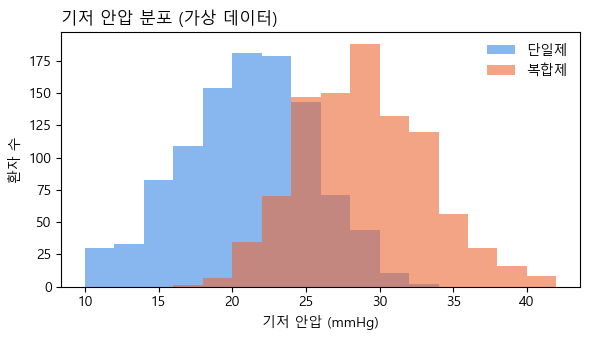

21~28 mmHg 구간 환자 수: {'단일제': 486, '복합제': 407}


In [4]:
BINS = np.arange(10, 43, 2)
print(df.groupby("combo")["iop0"].mean().rename(index=LABEL).round(1).to_frame("평균 기저 안압 (mmHg)"))

fig, ax = plt.subplots(figsize=(6, 3.5))
for k in [0, 1]:
    ax.hist(df.loc[df.combo == k, "iop0"], bins=BINS, alpha=0.6, color=COLOR[k], label=LABEL[k])
ax.set_xlabel("기저 안압 (mmHg)"); ax.set_ylabel("환자 수"); ax.legend(frameon=False)
ax.set_title("기저 안압 분포 (가상 데이터)", loc="left")
plt.tight_layout(); plt.show()

overlap = df[(df.iop0 >= 21) & (df.iop0 <= 28)]
print("21~28 mmHg 구간 환자 수:", overlap.groupby("combo").size().rename(index=LABEL).to_dict())

## 4. 성향점수와 1:1 매칭

공변량 4개로 로지스틱 회귀를 적합해 "복합제를 받을 확률"(성향점수)을 구합니다. 복합제 환자마다 로짓 성향점수가 가장 가까운 단일제 환자 1명을 짝짓습니다 (비복원, 허용 거리 = 로짓 성향점수 표준편차 x 0.2).

In [5]:
COVARS = ["iop0", "age", "ntg", "cct"]
ps_model = LogisticRegression(max_iter=1000).fit(df[COVARS], df["combo"])
df["ps"] = ps_model.predict_proba(df[COVARS])[:, 1]
df["logit_ps"] = np.log(df["ps"] / (1 - df["ps"]))
caliper = 0.2 * df["logit_ps"].std()

treated = df[df.combo == 1].sample(frac=1, random_state=0)   # 매칭 순서 무작위화
available = df.loc[df.combo == 0, "logit_ps"].to_dict()      # 아직 짝이 없는 단일제 환자

pairs = []
for t_idx, t_lps in treated["logit_ps"].items():
    if not available:
        break
    c_idx = np.array(list(available.keys()))
    c_lps = np.array(list(available.values()))
    j = np.argmin(np.abs(c_lps - t_lps))
    if abs(c_lps[j] - t_lps) <= caliper:
        pairs.append((t_idx, c_idx[j]))
        del available[c_idx[j]]

matched_t = df.loc[[p[0] for p in pairs]]
matched_c = df.loc[[p[1] for p in pairs]]
matched = pd.concat([matched_t, matched_c])
print(f"매칭된 쌍: {len(pairs)}쌍 (복합제 환자 {int(df.combo.sum())}명 중)")

매칭된 쌍: 377쌍 (복합제 환자 960명 중)


## 5. 균형 확인 (SMD, 0.1 미만이면 균형)

In [6]:
def smd(data, var):
    a = data.loc[data.combo == 1, var]
    b = data.loc[data.combo == 0, var]
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

balance = pd.DataFrame({"매칭 전": [smd(df, v) for v in COVARS],
                        "매칭 후": [smd(matched, v) for v in COVARS]}, index=COVARS).round(2)
balance

,매칭 전,매칭 후
iop0,1.83,0.05
age,0.18,0.03
ntg,-0.41,0.01
cct,0.21,-0.03


## 6. 매칭 후 결과

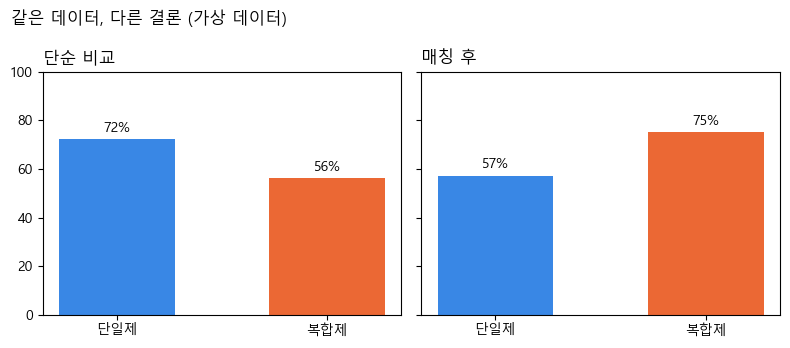

단순 비교: 단일제 72.5%  vs  복합제 56.1%
매칭 후  : 단일제 57.3%  vs  복합제 75.1%


In [7]:
after = matched.groupby("combo")["reach"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharey=True)
for ax, data, title in zip(axes, [naive, after], ["단순 비교", "매칭 후"]):
    bars = ax.bar([LABEL[k] for k in data.index], data.values,
                  color=[COLOR[k] for k in data.index], width=0.55)
    ax.bar_label(bars, fmt="%.0f%%", padding=3)
    ax.set_title(title, loc="left"); ax.set_ylim(0, 100)
fig.suptitle("같은 데이터, 다른 결론 (가상 데이터)", x=0.02, ha="left")
plt.tight_layout(); plt.show()
print(f"단순 비교: 단일제 {naive[0]:.1f}%  vs  복합제 {naive[1]:.1f}%")
print(f"매칭 후  : 단일제 {after[0]:.1f}%  vs  복합제 {after[1]:.1f}%")

## 7. 영상용 수치 내보내기

영상에 나오는 모든 숫자와 그래프는 아래 json에서 읽습니다.

In [8]:
def hist(series):
    return np.histogram(series, bins=BINS)[0].tolist()

numbers = {
    "note": f"가상 시뮬레이션 데이터 (seed={SEED}, N={N})",
    "target_iop": TARGET,
    "n": {"mono": int((df.combo == 0).sum()), "combo": int((df.combo == 1).sum())},
    "baseline_iop_mean": {"mono": round(df.loc[df.combo == 0, "iop0"].mean(), 1),
                          "combo": round(df.loc[df.combo == 1, "iop0"].mean(), 1)},
    "naive_reach_pct": {"mono": round(naive[0], 1), "combo": round(naive[1], 1)},
    "overlap_21_28": {"mono": int(((df.combo == 0) & df.iop0.between(21, 28)).sum()),
                      "combo": int(((df.combo == 1) & df.iop0.between(21, 28)).sum())},
    "matched_pairs": len(pairs),
    "matched_baseline_iop_mean": {"mono": round(matched_c["iop0"].mean(), 1),
                                  "combo": round(matched_t["iop0"].mean(), 1)},
    "matched_reach_pct": {"mono": round(after[0], 1), "combo": round(after[1], 1)},
    "smd": {v: {"before": float(balance.loc[v, "매칭 전"]), "after": float(balance.loc[v, "매칭 후"])}
            for v in COVARS},
    "iop0_hist": {
        "bins": BINS.tolist(),
        "before": {"mono": hist(df.loc[df.combo == 0, "iop0"]), "combo": hist(df.loc[df.combo == 1, "iop0"])},
        "after": {"mono": hist(matched_c["iop0"]), "combo": hist(matched_t["iop0"])},
    },
}
out = DATA_DIR / "psm_numbers.json"
out.write_text(json.dumps(numbers, ensure_ascii=False, indent=2), encoding="utf-8")
print(out.relative_to(TOPIC_DIR))
numbers

data\psm_numbers.json


{'note': '가상 시뮬레이션 데이터 (seed=0, N=2000)',
 'target_iop': 18,
 'n': {'mono': 1040, 'combo': 960},
 'baseline_iop_mean': {'mono': 21.0, 'combo': 28.9},
 'naive_reach_pct': {'mono': 72.5, 'combo': 56.1},
 'overlap_21_28': {'mono': 486, 'combo': 407},
 'matched_pairs': 377,
 'matched_baseline_iop_mean': {'mono': 25.1, 'combo': 25.3},
 'matched_reach_pct': {'mono': 57.3, 'combo': 75.1},
 'smd': {'iop0': {'before': 1.83, 'after': 0.05},
  'age': {'before': 0.18, 'after': 0.03},
  'ntg': {'before': -0.41, 'after': 0.01},
  'cct': {'before': 0.21, 'after': -0.03}},
 'iop0_hist': {'bins': [10,
   12,
   14,
   16,
   18,
   20,
   22,
   24,
   26,
   28,
   30,
   32,
   34,
   36,
   38,
   40,
   42],
  'before': {'mono': [30,
    33,
    83,
    109,
    154,
    181,
    179,
    143,
    71,
    44,
    11,
    2,
    0,
    0,
    0,
    0],
   'combo': [0, 0, 0, 1, 7, 35, 70, 147, 150, 188, 132, 120, 56, 30, 16, 8]},
  'after': {'mono': [0, 0, 0, 2, 7, 31, 72, 137, 71, 44, 11, 2, 0, 0, 